<a href="https://colab.research.google.com/github/Hank070131/insulin-compare/blob/main/%E5%B7%A8%E9%A1%8D%E5%B7%A5%E7%A8%8B%E9%80%BE%E6%9C%9F%E6%A1%88%E4%BB%B6%E5%88%86%E6%9E%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 巨額公共工程逾期未完工案件之特性分析

資料來源：政府資料開放平臺「巨額工程標案逾期6個月未完工案件明細表」（行政院公共工程委員會）
https://data.gov.tw/dataset/158101

分析內容：
1. 逾期工程的實際進度分布
2. 契約金額級距與開工至今年數
3. 逾期案件數最多的主管機關

## 1. 準備工具與中文字型

In [1]:
!apt-get -qq install -y fonts-noto-cjk > /dev/null   # 安裝中文字型

import pandas as pd                     # 處理表格
import matplotlib.pyplot as plt         # 畫圖
import matplotlib.font_manager as fm
from google.colab import files          # 上傳、下載檔案

# 讓圖表可以顯示中文
fm.fontManager.addfont('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')
plt.rcParams['font.family'] = 'Noto Sans CJK JP'

## 2. 上傳並讀取資料

In [2]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]    # 取得上傳的檔案名稱
df = pd.read_csv(file_name, encoding='utf-8-sig')

df.columns = ['主管機關', '執行機關', '標案名稱', '得標廠商', '金額', '開工日', '完工日', '進度']
print('總共', len(df), '筆')
df.head()

Saving 巨額工程標案逾期6個月未完工案件明細表.CSV to 巨額工程標案逾期6個月未完工案件明細表.CSV
總共 68 筆


,主管機關,執行機關,標案名稱,得標廠商,金額,開工日,完工日,進度
0,NaN,台灣中油股份有限公司煉製事業部大林煉油廠,大林廠第三重油加氫脫硫工場復建工程,中鼎工程股份有限公司,3568000.000,1121006,1150404.0,100.00
1,NaN,國防部軍備局工程營產中心,陸軍「漢陽營區既有植栽處理工程」,樹景園藝-,35164.900,1131011,1141110.0,99.60
2,NaN,宜蘭縣政府建設處,宜蘭縣立圖書館新建工程,成發營造有限公司,522662.789,1120515,1150308.0,100.00
3,NaN,新竹縣政府工務處新建工程科,縣道120線23K+640~24K+850道路拓寬改善工程,金春福營造股份有限公司,344633.327,1130411,NaN,76.35
4,中央研究院,中央研究院,南部院區公共工程及第1棟建築興建工程,根基營造股份有限公司,1754889.871,1071116,1090915.0,100.00


## 3. 把民國日期轉成西元日期

In [3]:
def roc_to_date(x):
    if pd.isna(x):                      # 空白就回傳空白日期
        return pd.NaT
    x = str(int(x))                     # 1121006.0 → '1121006'
    year = int(x[:-4]) + 1911           # '112' → 2023
    month = int(x[-4:-2])               # '10'
    day = int(x[-2:])                   # '06'
    return pd.Timestamp(year, month, day)

df['開工日'] = df['開工日'].apply(roc_to_date)
df['完工日'] = df['完工日'].apply(roc_to_date)

## 4. 計算摘要數字

In [4]:
today = pd.Timestamp.today()            # 以今天為基準日
df['開工至今年數'] = (today - df['開工日']).dt.days / 365
df['逾期天數'] = (today - df['完工日']).dt.days   # 完工日空白的會是空白

done = df[df['進度'] >= 100]            # 進度已達 100% 的工程
n_prog = df['進度'].notna().sum()       # 有填進度的件數（算比例用）

print('總件數：', len(df))
print('進度 100% 但未結案：', len(done), '件，佔', round(len(done) / n_prog * 100, 1), '%')
print('開工至今年數中位數：', round(df['開工至今年數'].median(), 1), '年')
print('有完工日的件數：', df['逾期天數'].notna().sum())
print('逾期天數中位數：', df['逾期天數'].median(), '天')

總件數： 68
進度 100% 但未結案： 16 件，佔 24.2 %
開工至今年數中位數： 4.1 年
有完工日的件數： 34
逾期天數中位數： 380.5 天


## 5. 圖一：逾期工程的實際進度分布

進度分組
未滿50%         6
50–80%        7
80–未滿100%    37
100%         16
Name: count, dtype: int64


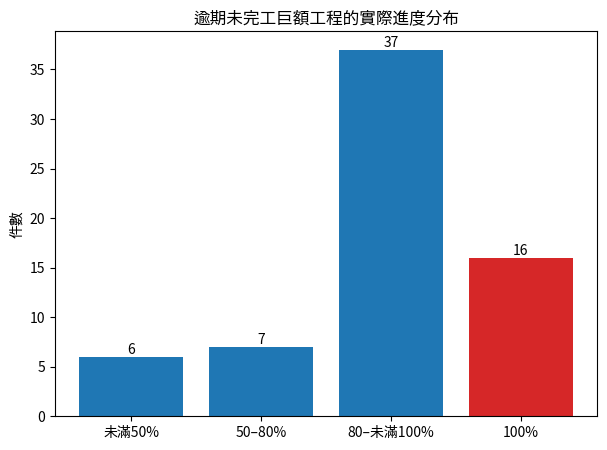

In [5]:
bins = [0, 50, 80, 99.99, 100]          # 分組切點
labels = ['未滿50%', '50–80%', '80–未滿100%', '100%']
df['進度分組'] = pd.cut(df['進度'], bins=bins, labels=labels, include_lowest=True)
count = df['進度分組'].value_counts().reindex(labels)   # 每組件數
print(count)

plt.figure(figsize=(7, 5))
plt.bar(labels, count, color=['tab:blue', 'tab:blue', 'tab:blue', 'tab:red'])
for i, v in enumerate(count):           # 在每根長條上寫件數
    plt.text(i, v + 0.3, str(v), ha='center')
plt.ylabel('件數')
plt.title('逾期未完工巨額工程的實際進度分布')
plt.savefig('fig1.png', dpi=200)
plt.show()

## 6. 圖二：契約金額與開工至今年數

       件數  開工至今年數中位數
金額級距                
未滿5億   17        3.4
5–10億  14        3.7
10億以上  23        6.8


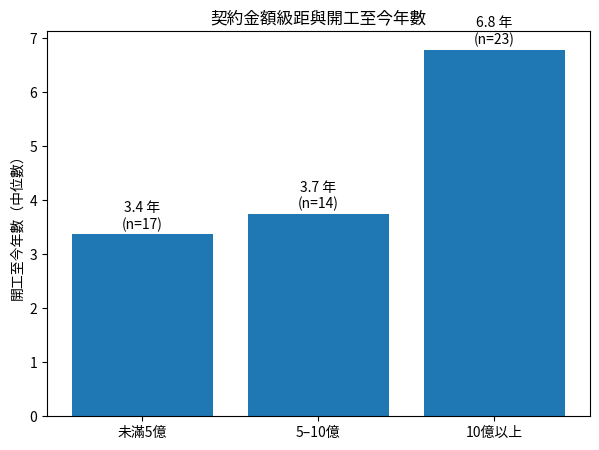

In [6]:
bins = [0, 500000, 1000000, 1e12]       # 單位千元
labels = ['未滿5億', '5–10億', '10億以上']
df['金額級距'] = pd.cut(df['金額'], bins=bins, labels=labels)

years = df.groupby('金額級距', observed=False)['開工至今年數'].median()   # 各組中位數
n = df.groupby('金額級距', observed=False)['開工至今年數'].count()        # 各組件數
print(pd.DataFrame({'件數': n, '開工至今年數中位數': years.round(1)}))

plt.figure(figsize=(7, 5))
plt.bar(labels, years, color='tab:blue')
for i, (v, c) in enumerate(zip(years, n)):   # 長條上寫年數和件數
    plt.text(i, v + 0.1, f'{v:.1f} 年\n(n={c})', ha='center')
plt.ylabel('開工至今年數（中位數）')
plt.title('契約金額級距與開工至今年數')
plt.savefig('fig2.png', dpi=200)
plt.show()

## 7. 圖三：逾期案件數最多的主管機關

機關
交通部      11
國防部       9
經濟部       6
臺北市政府     6
農業部       3
雲林縣政府     3
桃園市政府     3
外交部       2
中央研究院     2
高雄市政府     2
Name: count, dtype: int64


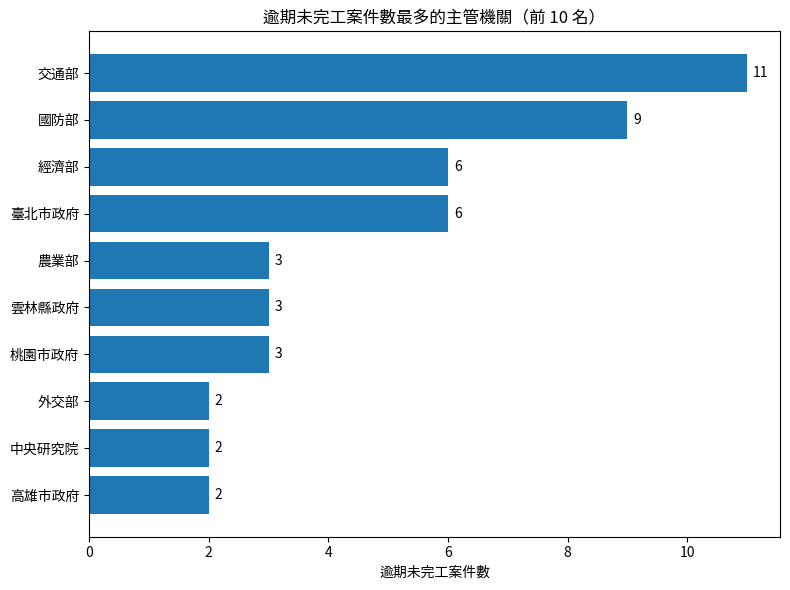

In [7]:
def merge_agency(name):
    """把下屬單位合併到上級機關，例：國防部陸軍司令部 → 國防部"""
    if pd.isna(name):
        return name
    for key in ['國防部', '農業部']:
        if name.startswith(key):
            return key
    if name.startswith('雲林縣'):
        return '雲林縣政府'
    if '政府' in name:
        return name[:name.index('政府') + 2]
    return name

df['機關'] = df['主管機關'].apply(merge_agency)
top = df['機關'].value_counts().head(10)    # 件數前 10 名
print(top)

plt.figure(figsize=(8, 6))
plt.barh(top.index[::-1], top.values[::-1], color='tab:blue')   # [::-1] 讓第一名在最上面
for i, v in enumerate(top.values[::-1]):
    plt.text(v + 0.1, i, str(v), va='center')
plt.xlabel('逾期未完工案件數')
plt.title('逾期未完工案件數最多的主管機關（前 10 名）')
plt.tight_layout()
plt.savefig('fig3.png', dpi=200)
plt.show()

## 8. 下載三張圖

In [8]:
files.download('fig1.png')
files.download('fig2.png')
files.download('fig3.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>